## Setup

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import config
from core.logger import get_logger
from core import preprocessing as prep
from core import classical_models as clf
from core import robustness as rob

warnings.filterwarnings("ignore")
config.ensure_dirs()

logger = get_logger("notebook")
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 120
RED, GREEN = "#e74c3c", "#2ecc71"

print("Output directories ready:", config.OUTPUT_DIR, config.ARTIFACT_DIR)

Output directories ready: outputs artifacts


## Dataset Loading

In [2]:
df_raw = prep.load_dataset(config.TRUE_CSV, config.FAKE_CSV)
print("Raw shape:", df_raw.shape)
df_raw.head(3)

Raw shape: (44898, 6)


,title,text,subject,date,label,label_name
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017",1,Real
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017",1,Real
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017",1,Real


### Noise Detection

In [3]:
total_records = len(df_raw)

noise_records = df_raw[
    df_raw["text"].isna() |
    (df_raw["text"].str.strip() == "")
].shape[0]

noise_percentage = (noise_records / total_records) * 100

print("Total records:", total_records)
print("Noise records:", noise_records)
print(f"Noise percentage: {noise_percentage:.2f}%")

Total records: 44898
Noise records: 631
Noise percentage: 1.41%


## Data Quality Assessment

In [4]:
quality = prep.assess_data_quality(df_raw)
quality.to_csv(f"{config.OUTPUT_DIR}/data_quality_summary.csv")
print("Exact duplicate rows:", quality.attrs["exact_duplicate_rows"])
print("Duplicate (title, text) rows:", quality.attrs["duplicate_title_text_rows"])
quality[quality["missing_count"] > 0]

Exact duplicate rows: 209
Duplicate (title, text) rows: 5793


,missing_count,missing_pct,dtype


## Data Cleaning -- Deduplication and Null/Blank Removal

In [5]:
df = prep.clean_dataset(df_raw)
print("Cleaned shape:", df.shape)
df["label_name"].value_counts()

Cleaned shape: (38658, 6)


label_name
Real    21196
Fake    17462
Name: count, dtype: int64

## Feature Engineering -- Structural and Stylistic Features

In [6]:
df = prep.engineer_eda_features(df)
df[["char_count", "word_count", "title_word_count", "title_caps_ratio", "title_exclaim"]].describe().round(3)

,char_count,word_count,title_word_count,title_caps_ratio,title_exclaim
count,38658.000,38658.000,38658.000,38658.000,38658.000
mean,2456.107,403.131,11.925,0.193,0.056
std,1936.767,313.869,3.658,0.180,0.254
min,5.000,1.000,1.000,0.000,0.000
25%,1318.000,216.000,9.000,0.058,0.000
50%,2227.000,369.000,11.000,0.115,0.000
75%,3096.000,511.000,14.000,0.290,0.000
max,51794.000,8135.000,42.000,1.000,4.000


## Exploratory Data Analysis

### EDA 1. Class Distribution

In [7]:
counts = df["label_name"].value_counts()
print(counts)
print("Class ratio (Fake:Real):", round(counts["Fake"] / counts["Real"], 3))

label_name
Real    21196
Fake    17462
Name: count, dtype: int64
Class ratio (Fake:Real): 0.824


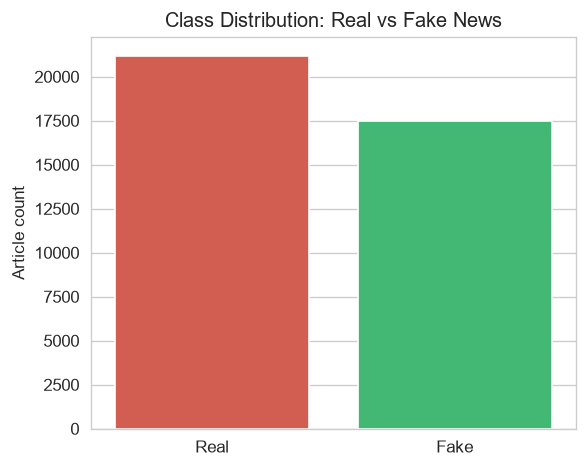

In [8]:
plt.figure(figsize=(5, 4))
sns.countplot(data=df, x="label_name", hue="label_name", palette=[RED, GREEN], legend=False)
plt.title("Class Distribution: Real vs Fake News"); plt.xlabel(""); plt.ylabel("Article count")
plt.tight_layout(); plt.savefig(f"{config.OUTPUT_DIR}/fig1_class_distribution.png", dpi=150); plt.show()

### EDA 2. Subject/Category Distribution by Class

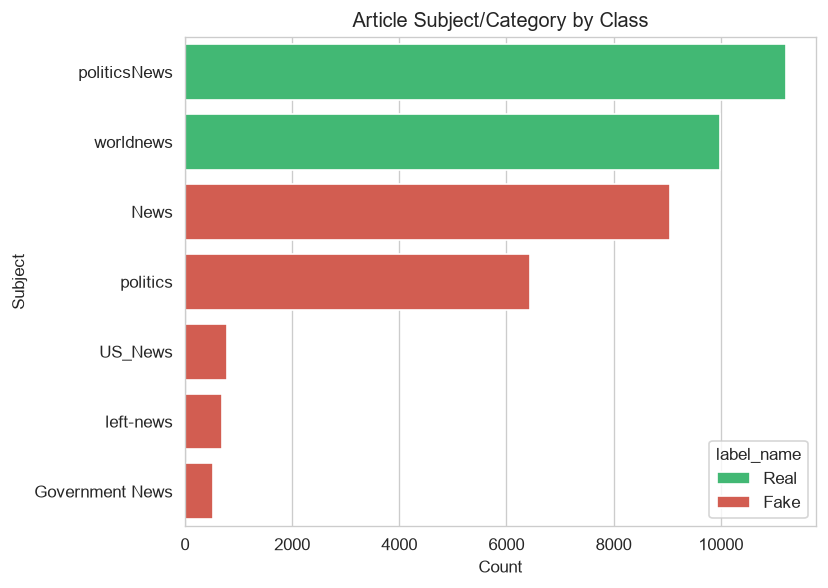

In [9]:
plt.figure(figsize=(7, 5))
order = df["subject"].value_counts().index
sns.countplot(data=df, y="subject", hue="label_name", order=order, palette=[GREEN, RED])
plt.title("Article Subject/Category by Class"); plt.xlabel("Count"); plt.ylabel("Subject")
plt.tight_layout(); plt.savefig(f"{config.OUTPUT_DIR}/fig2_subject_distribution.png", dpi=150); plt.show()

In [10]:
df.groupby("subject")["label_name"].value_counts().unstack(fill_value=0)

label_name,Real,Fake
subject,,
Government News,0,515
News,0,9050
US_News,0,783
left-news,0,684
politics,0,6430
politicsNews,11216,0
worldnews,9980,0


### EDA 3. Temporal Distribution - converts dates

In [11]:
df["date_parsed"] = pd.to_datetime(df["date"], errors="coerce")
df["year_month"] = df["date_parsed"].dt.to_period("M")
monthly = df.groupby(["year_month", "label_name"], observed=True).size().unstack(fill_value=0)

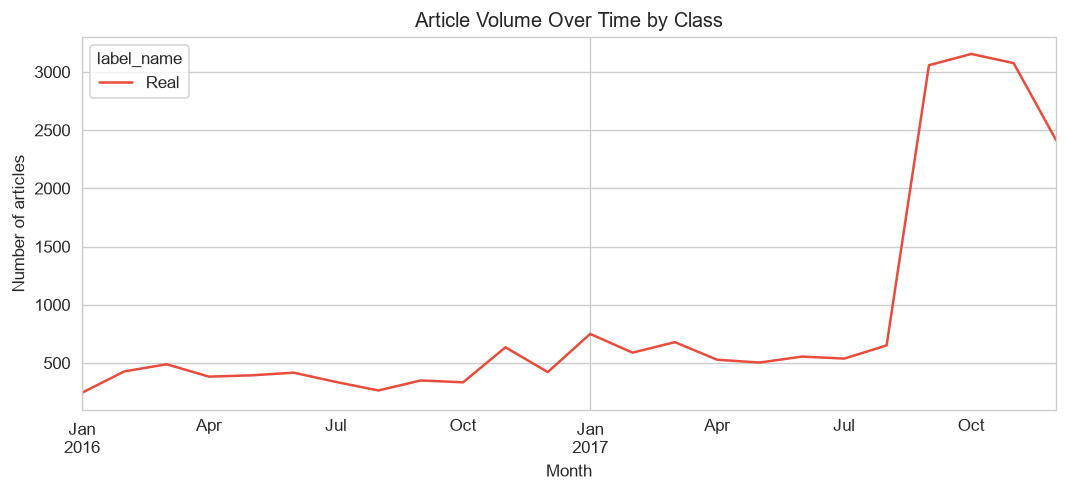

In [12]:
### time graph
monthly.plot(figsize=(9, 4.2), color=[RED, GREEN])
plt.title("Article Volume Over Time by Class"); plt.xlabel("Month"); plt.ylabel("Number of articles")
plt.tight_layout(); plt.savefig(f"{config.OUTPUT_DIR}/fig3_articles_over_time.png", dpi=150); plt.show()  #dpi- image quality

### EDA 4. Body Text Length Analysis

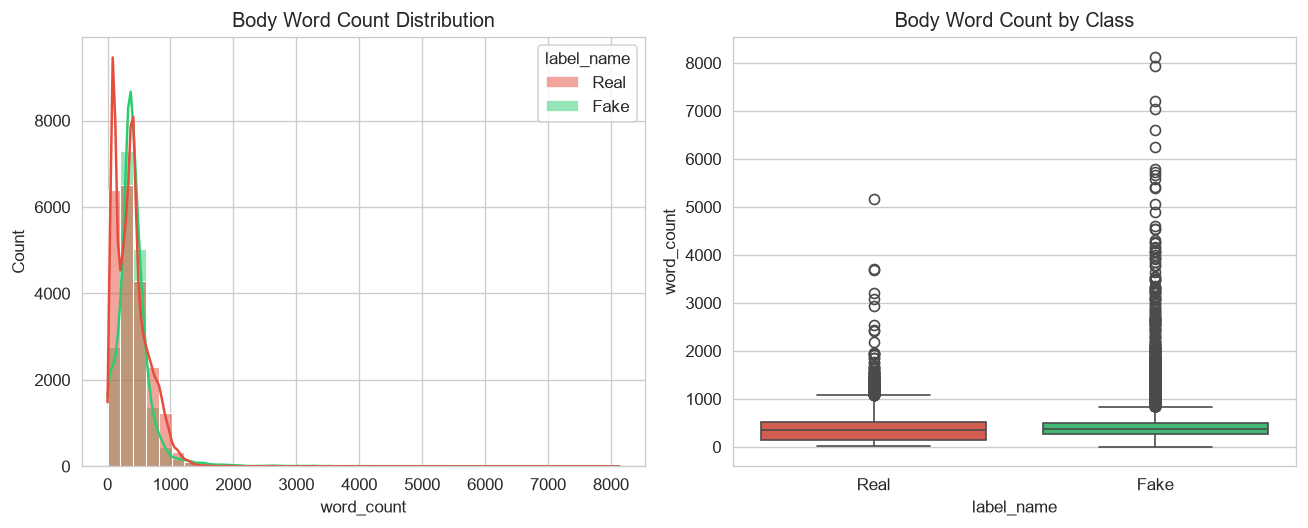

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
sns.histplot(data=df, x="word_count", hue="label_name", bins=40, kde=True, palette=[RED, GREEN], ax=axes[0])
axes[0].set_title("Body Word Count Distribution")
sns.boxplot(data=df, x="label_name", y="word_count", hue="label_name", palette=[RED, GREEN], legend=False, ax=axes[1])
axes[1].set_title("Body Word Count by Class")
plt.tight_layout(); plt.savefig(f"{config.OUTPUT_DIR}/fig4_word_count.png", dpi=150); plt.show()

In [14]:
df.groupby("label_name")[["word_count", "char_count", "title_word_count"]].describe().T.round(1)
### calculte word, char count

label_name                 Fake     Real
word_count       count  17462.0  21196.0
                 mean     425.3    384.9
                 std      355.2    273.8
                 min        1.0     22.0
                 25%      277.0    147.0
                 50%      376.0    359.0
                 75%      503.0    523.0
                 max     8135.0   5172.0
char_count       count  17462.0  21196.0
                 mean    2549.9   2378.8
                 std     2201.4   1684.0
                 min        5.0    152.0
                 25%     1648.2    906.8
                 50%     2235.0   2217.0
                 75%     3005.8   3227.5
                 max    51794.0  29781.0
title_word_count count  17462.0  21196.0
                 mean      14.3     10.0
                 std        4.0      1.7
                 min        1.0      4.0
                 25%       12.0      9.0
                 50%       14.0     10.0
                 75%       16.0     11.0
                 max       42.0     20.0

### EDA 5. Title Characteristics -- ALL-CAPS Ratio and Exclamation Marks

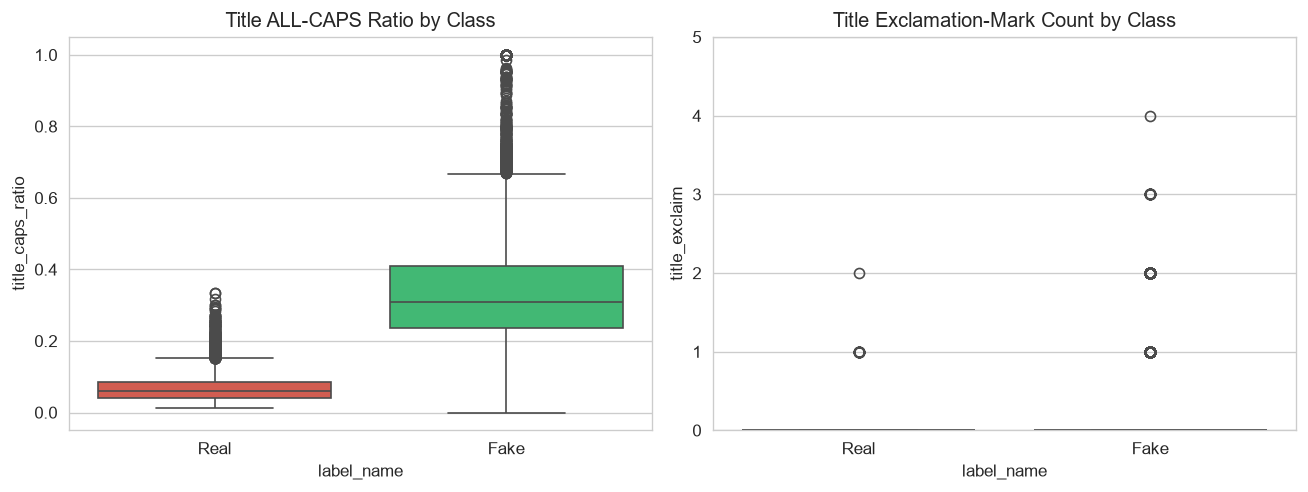

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
sns.boxplot(data=df, x="label_name", y="title_caps_ratio", hue="label_name", palette=[RED, GREEN], legend=False, ax=axes[0])
axes[0].set_title("Title ALL-CAPS Ratio by Class")
sns.boxplot(data=df, x="label_name", y="title_exclaim", hue="label_name", palette=[RED, GREEN], legend=False, ax=axes[1])
axes[1].set_title("Title Exclamation-Mark Count by Class"); axes[1].set_ylim(0, 5)
plt.tight_layout(); plt.savefig(f"{config.OUTPUT_DIR}/fig5_title_style.png", dpi=150); plt.show()

In [16]:
df.groupby("label_name")[["title_caps_ratio", "title_exclaim"]].mean().round(4)

,title_caps_ratio,title_exclaim
label_name,,
Fake,0.3464,0.1226
Real,0.0669,0.0009


## EDA Checkpoint

In [17]:
df.drop(columns=["date_parsed", "year_month"]).to_csv(config.CLEANED_DATASET_PATH, index=False)
print(f"Saved {len(df):,} rows -> {config.CLEANED_DATASET_PATH}")

Saved 38,658 rows -> data/news_cleaned.csv


## Modelling Data Preparation

In [18]:
df = pd.read_csv(config.CLEANED_DATASET_PATH)
df = prep.clean_text_for_modelling(df, min_word_count=config.MIN_CLEAN_WORD_COUNT)
print("Modelling-ready shape:", df.shape)

Modelling-ready shape: (38653, 14)


In [19]:
df.to_csv(config.MODEL_READY_PATH, index=False)
print(f"Saved -> {config.MODEL_READY_PATH}")
df[["clean_text", "clean_word_count", "label_name"]].head(3)

Saved -> data/news_model_ready.csv


,clean_text,clean_word_count,label_name
0,head conservative republican faction congress ...,434,Real
1,military accept transgender recruit monday pen...,381,Real
2,senior republican senator let mueller job wash...,263,Real


## Train/Test Split

In [20]:
idx_train, idx_test = prep.stratified_split(df, test_size=config.TEST_SIZE, random_state=config.RANDOM_STATE)
X_text = prep.text_array(df)
y = df["label"].to_numpy()
print(f"Train: {len(idx_train):,} articles  |  Test: {len(idx_test):,} articles")
print("Train class balance:", np.bincount(y[idx_train]), " Test class balance:", np.bincount(y[idx_test]))

Train: 30,922 articles  |  Test: 7,731 articles
Train class balance: [13965 16957]  Test class balance: [3492 4239]


## Classical Machine Learning Baselines

In [21]:
tfidf = clf.build_tfidf(max_features=config.TFIDF_MAX_FEATURES,
                        ngram_range=config.TFIDF_NGRAM_RANGE, min_df=config.TFIDF_MIN_DF)
X_train = tfidf.fit_transform(X_text[idx_train])
X_test = tfidf.transform(X_text[idx_test])
y_train, y_test = y[idx_train], y[idx_test]
print("TF-IDF matrix:", X_train.shape)

TF-IDF matrix: (30922, 15000)


In [22]:
classical_metrics, classical_fitted = clf.fit_all_classifiers(X_train, y_train, X_test, y_test,
                                                               random_state=config.RANDOM_STATE)
metrics_df = pd.DataFrame(classical_metrics).T.round(4)
metrics_df.to_csv(f"{config.OUTPUT_DIR}/classical_model_metrics.csv")
metrics_df

,accuracy,precision,recall,f1,roc_auc
Logistic Regression,0.9897,0.9851,0.9962,0.9906,0.9994
Multinomial Naive Bayes,0.9521,0.9553,0.9575,0.9564,0.9891
Random Forest,0.9842,0.9791,0.9925,0.9857,0.9989


In [23]:
for name, model in classical_fitted.items():
    slug = name.lower().replace(" ", "_")
    joblib_path = f"{config.ARTIFACT_DIR}/{slug}.joblib"
    import joblib
    joblib.dump(model, joblib_path)
joblib.dump(tfidf, f"{config.ARTIFACT_DIR}/tfidf_vectorizer.joblib")
print("Saved:", list(classical_fitted.keys()), "+ tfidf_vectorizer")

Saved: ['Logistic Regression', 'Multinomial Naive Bayes', 'Random Forest'] + tfidf_vectorizer


### 5-Fold Stratified Cross-Validation

In [24]:
cv_result = clf.cross_validate_logreg(X_text, y, n_splits=5, random_state=config.RANDOM_STATE,
                                       tfidf_kwargs=dict(max_features=config.TFIDF_MAX_FEATURES,
                                                          ngram_range=config.TFIDF_NGRAM_RANGE,
                                                          min_df=config.TFIDF_MIN_DF))
import json
with open(f"{config.OUTPUT_DIR}/cv_result.json", "w") as f:
    json.dump(cv_result, f, indent=2)
pd.DataFrame(cv_result["folds"])

,fold,accuracy,f1,roc_auc
0,1,0.9917,0.9925,0.9992
1,2,0.9912,0.9920,0.9995
2,3,0.9911,0.9919,0.9993
3,4,0.9908,0.9917,0.9995
4,5,0.9939,0.9945,0.9997


In [25]:
pd.DataFrame(cv_result["summary"]).T.round(4)

,mean,std
accuracy,0.9917,0.0011
f1,0.9925,0.0010
roc_auc,0.9994,0.0002


### Classical Model Comparison Plot

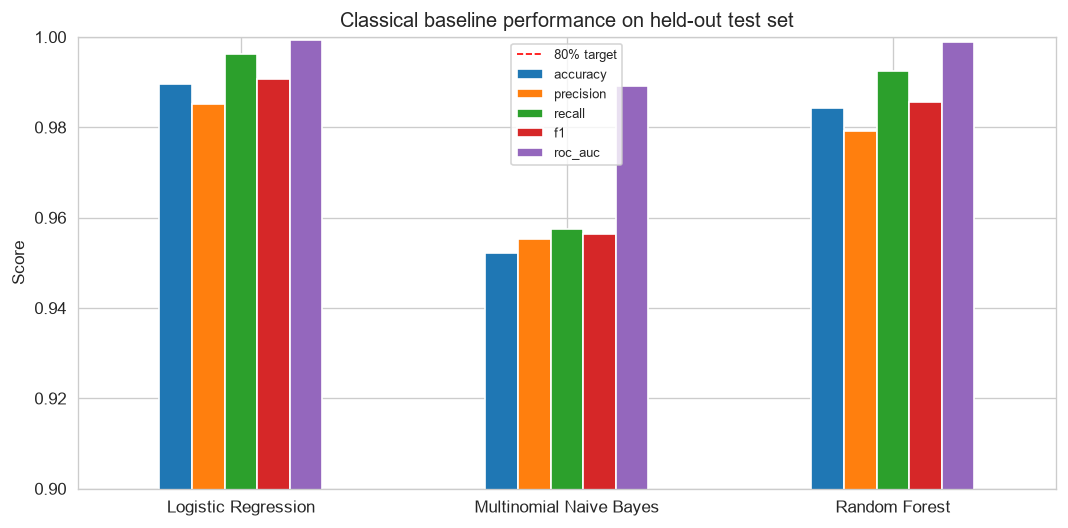

In [26]:
metrics_df[["accuracy", "precision", "recall", "f1", "roc_auc"]].plot(kind="bar", figsize=(9, 4.5))
plt.axhline(config.PERFORMANCE_TARGET, color="red", linestyle="--", linewidth=1, label=f"{config.PERFORMANCE_TARGET:.0%} target")
plt.ylabel("Score"); plt.title("Classical baseline performance on held-out test set")
plt.ylim(0.90, 1.0); plt.legend(fontsize=8); plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig(f"{config.OUTPUT_DIR}/fig6_classical_comparison.png", dpi=150); plt.show()

### ROC Curves

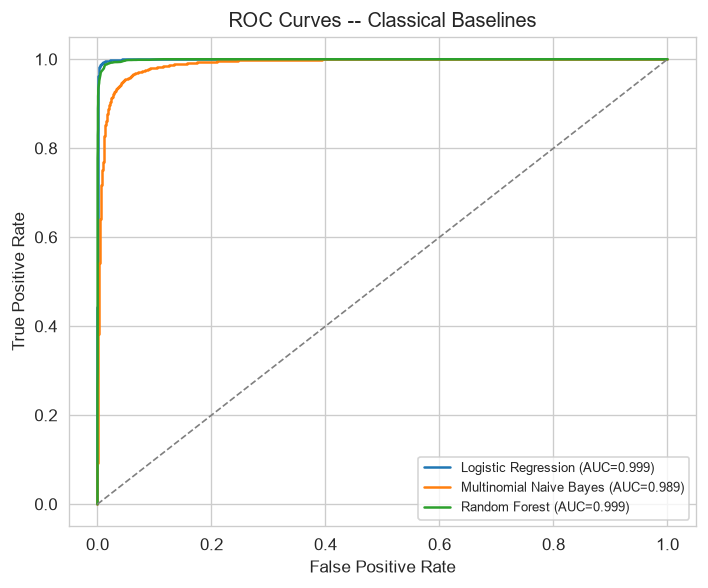

In [27]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, model in classical_fitted.items():
    fpr, tpr, auc = clf.get_roc_curve(model, X_test, y_test)
    ax.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")
ax.plot([0, 1], [0, 1], "--", color="grey", linewidth=1)
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curves -- Classical Baselines"); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig(f"{config.OUTPUT_DIR}/roc_classical.png", dpi=150); plt.show()

### Classical Baselines -- Train vs. Test Gap (Overfitting Check)

In [28]:

train_vs_test = pd.DataFrame({
    "train_accuracy": {name: model.score(X_train, y_train) for name, model in classical_fitted.items()},
    "test_accuracy": metrics_df["accuracy"],
})
train_vs_test["gap"] = (train_vs_test["train_accuracy"] - train_vs_test["test_accuracy"]).round(4)
train_vs_test["overfitting"] = train_vs_test["gap"] > 0.03
train_vs_test.round(4)

,train_accuracy,test_accuracy,gap,overfitting
Logistic Regression,0.9984,0.9897,0.0087,False
Multinomial Naive Bayes,0.9626,0.9521,0.0105,False
Random Forest,1.0000,0.9842,0.0158,False


## Deep Learning Data Preparation -- Tokenisation

In [29]:
import json

import tensorflow as tf
from core import deep_models as dm

df = pd.read_csv(config.MODEL_READY_PATH)
idx_train, idx_test = prep.stratified_split(df, test_size=config.TEST_SIZE, random_state=config.RANDOM_STATE)
X_text = prep.text_array(df)
y = df["label"].to_numpy()

tokenizer, X_train_seq, X_test_seq = dm.tokenize_and_pad(
    X_text[idx_train], X_text[idx_test], vocab_size=config.VOCAB_SIZE, max_len=config.MAX_LEN)
y_train, y_test = y[idx_train], y[idx_test]
dm.save_tokenizer(tokenizer, f"{config.ARTIFACT_DIR}/tokenizer.pkl")
print("Vocabulary observed:", len(tokenizer.word_index), "| sequence shape:", X_train_seq.shape)

Vocabulary observed: 91653 | sequence shape: (30922, 180)


### Overfitting Guard 

In [30]:
def train_with_overfit_guard(model, X_train_seq, y_train, X_test_seq, y_test,
                              val_fraction=0.10, epochs=15, batch_size=256,
                              patience=2, random_state=42):
    """
    Trains with two overfitting safeguards and evaluates once on the held-out
    test set. Returns (history_dict, test_metrics_dict, train_time_s, stopped_early: bool).
    """
    import time
    from tensorflow.keras import callbacks

    rng = np.random.RandomState(random_state)
    perm = rng.permutation(len(X_train_seq))
    val_n = int(val_fraction * len(X_train_seq))
    val_idx, tr_idx = perm[:val_n], perm[val_n:]

    early_stop = callbacks.EarlyStopping(monitor="val_loss", patience=patience,
                                          restore_best_weights=True, verbose=1)
    reduce_lr = callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                             patience=1, min_lr=1e-5, verbose=1)

    t0 = time.time()
    hist = model.fit(X_train_seq[tr_idx], y_train[tr_idx],
                      validation_data=(X_train_seq[val_idx], y_train[val_idx]),
                      epochs=epochs, batch_size=batch_size,
                      callbacks=[early_stop, reduce_lr], verbose=2)
    train_time = time.time() - t0
    stopped_early = early_stop.stopped_epoch > 0

    test_metrics = model.evaluate(X_test_seq, y_test, verbose=0, return_dict=True)
    history = {k: [float(v) for v in vals] for k, vals in hist.history.items()}

    if stopped_early:
        print(f"Overfitting guard triggered -> stopped at epoch {early_stop.stopped_epoch + 1}, "
              "best-val-loss weights restored.")
    else:
        print("Completed all scheduled epochs without the overfitting guard triggering.")
    return history, {k: float(v) for k, v in test_metrics.items()}, train_time, stopped_early


def plot_training_curves(history, title, save_path):
    """Loss/accuracy curves, plus the final train-val accuracy gap as a
    plain-language overfitting readout."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(history["loss"], label="train_loss"); axes[0].plot(history["val_loss"], label="val_loss")
    axes[0].set_title(f"{title} -- Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend()
    axes[1].plot(history["accuracy"], label="train_accuracy"); axes[1].plot(history["val_accuracy"], label="val_accuracy")
    axes[1].set_title(f"{title} -- Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].legend()
    plt.tight_layout(); plt.savefig(save_path, dpi=150); plt.show()

    gap = history["accuracy"][-1] - history["val_accuracy"][-1]
    verdict = "healthy fit" if abs(gap) < 0.02 else "watch for overfitting"
    print(f"Final train-val accuracy gap: {gap:.4f} ({verdict})")
    return gap

## Deep Learning Model -- Self-Trained BiLSTM-CNN-Attention Network

In [31]:
bilstm_model = dm.build_bilstm_cnn_attention(vocab_size=config.VOCAB_SIZE, max_len=config.MAX_LEN,
                                              embed_dim=config.EMBED_DIM)
bilstm_model.summary()

Model: "BiLSTM_CNN_Attention"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 180)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ embedding (Embedding)                │ (None, 180, 64)             │       1,280,000 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ spatial_dropout1d (SpatialDropout1D) │ (None, 180, 64)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d (Conv1D)                      │ (None, 180, 64)             │          20,544 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d (MaxPooling1D)         │ (None, 90, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bidirectional (Bidirectional)        │ (None, 90, 96)              │          43,392 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ attention (Attention)                │ (None, 96)                  │           4,705 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 32)                  │           3,104 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,351,778 (5.16 MB)

 Trainable params: 1,351,778 (5.16 MB)

 Non-trainable params: 0 (0.00 B)

In [32]:
bilstm_history, bilstm_test_metrics, bilstm_train_time, bilstm_stopped_early = train_with_overfit_guard(
    bilstm_model, X_train_seq, y_train, X_test_seq, y_test, random_state=config.RANDOM_STATE)

print("Training time (s):", round(bilstm_train_time, 1))
print("Test metrics:", {k: round(v, 4) for k, v in bilstm_test_metrics.items()})

Epoch 1/15
109/109 - 53s - 486ms/step - accuracy: 0.9193 - auc: 0.9800 - loss: 0.1898 - precision: 0.8992 - recall: 0.9606 - val_accuracy: 0.9884 - val_auc: 0.9988 - val_loss: 0.0325 - val_precision: 0.9900 - val_recall: 0.9888 - learning_rate: 0.0010
Epoch 2/15
109/109 - 32s - 292ms/step - accuracy: 0.9944 - auc: 0.9991 - loss: 0.0204 - precision: 0.9944 - recall: 0.9955 - val_accuracy: 0.9887 - val_auc: 0.9993 - val_loss: 0.0305 - val_precision: 0.9871 - val_recall: 0.9923 - learning_rate: 0.0010
Epoch 3/15
109/109 - 30s - 272ms/step - accuracy: 0.9976 - auc: 0.9997 - loss: 0.0083 - precision: 0.9975 - recall: 0.9982 - val_accuracy: 0.9909 - val_auc: 0.9984 - val_loss: 0.0272 - val_precision: 0.9894 - val_recall: 0.9941 - learning_rate: 0.0010
Epoch 4/15

Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
109/109 - 34s - 308ms/step - accuracy: 0.9988 - auc: 0.9998 - loss: 0.0045 - precision: 0.9986 - recall: 0.9992 - val_accuracy: 0.9890 - val_auc: 0.9959 - v

In [33]:
bilstm_model.save(f"{config.ARTIFACT_DIR}/bilstm_cnn_attention.keras")
with open(f"{config.OUTPUT_DIR}/bilstm_history.json", "w") as f:
    json.dump({"history": bilstm_history, "test_metrics": bilstm_test_metrics,
               "train_time_s": bilstm_train_time, "stopped_early": bilstm_stopped_early}, f, indent=2)

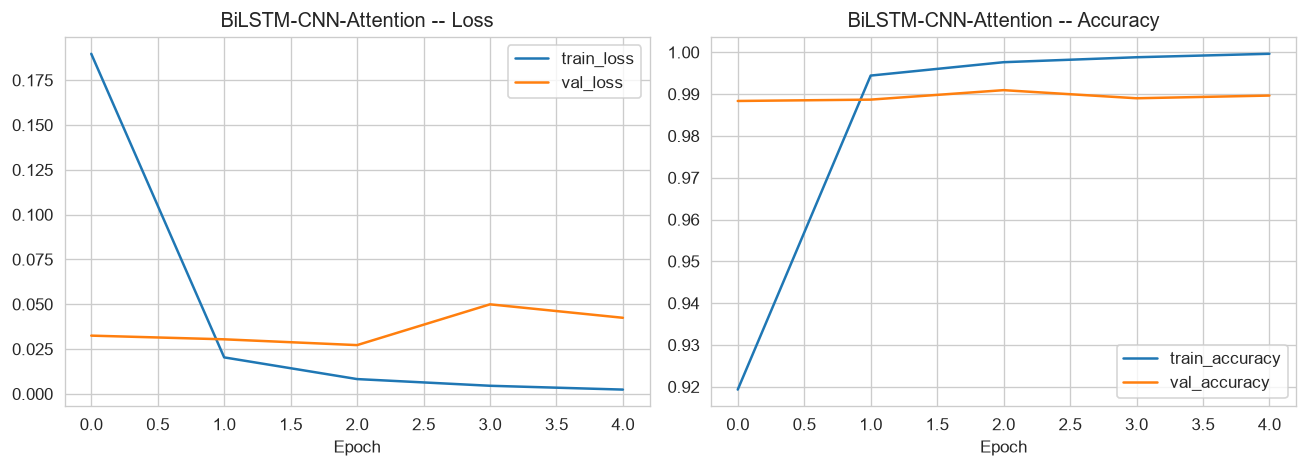

Final train-val accuracy gap: 0.0100 (healthy fit)


In [34]:
bilstm_gap = plot_training_curves(bilstm_history, "BiLSTM-CNN-Attention",
                                   f"{config.OUTPUT_DIR}/fig_bilstm_training_curves.png")

### BiLSTM -- Predict Immediately After the Overfitting Guard Stops Training

In [35]:
from core.inference import predict as run_prediction

bilstm_samples = [
    ("Senate passes budget bill after late-night vote",
     "WASHINGTON (Reuters) - The U.S. Senate passed a wide-ranging budget bill on Thursday after a marathon "
     "overnight session, sending the measure to the House for a final vote before the funding deadline."),
    ("SHOCKING: Doctors HATE this one weird trick that cures EVERYTHING overnight!!!",
     "You wont believe what secret elites dont want you to know. Share this before it gets deleted forever "
     "by the mainstream media conspiracy."),
]
for title, body in bilstm_samples:
    result = run_prediction(title, body, bilstm_model, tokenizer, max_len=config.MAX_LEN)
    print(f"{title[:55]!r:58} -> {result}")

'Senate passes budget bill after late-night vote'          -> {'label': 'Real', 'confidence': 0.9994, 'probability_real': 0.9994, 'probability_fake': 0.0006}
'SHOCKING: Doctors HATE this one weird trick that cures '  -> {'label': 'Fake', 'confidence': 1.0, 'probability_real': 0.0, 'probability_fake': 1.0}


## Deep Learning Model -- From-Scratch Transformer Encoder

In [36]:
transformer_model = dm.build_transformer_encoder(vocab_size=config.VOCAB_SIZE, max_len=config.MAX_LEN,
                                                  embed_dim=config.EMBED_DIM)
transformer_model.summary()

Model: "From_Scratch_Transformer_Encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 180)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ positional_embedding                 │ (None, 180, 64)             │       1,291,520 │
│ (PositionalEmbedding)                │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ transformer_block (TransformerBlock) │ (None, 180, 64)             │          29,344 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ transformer_block_1                  │ (None, 180, 64)             │          29,344 │
│ (TransformerBlock)                   │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling1d             │ (None, 64)                  │               0 │
│ (GlobalAveragePooling1D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_7 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 48)                  │           3,120 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_8 (Dropout)                  │ (None, 48)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 1)                   │              49 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,353,377 (5.16 MB)

 Trainable params: 1,353,377 (5.16 MB)

 Non-trainable params: 0 (0.00 B)

In [37]:
transformer_history, transformer_test_metrics, transformer_train_time, transformer_stopped_early = train_with_overfit_guard(
    transformer_model, X_train_seq, y_train, X_test_seq, y_test, random_state=config.RANDOM_STATE)

print("Training time (s):", round(transformer_train_time, 1))
print("Test metrics:", {k: round(v, 4) for k, v in transformer_test_metrics.items()})

Epoch 1/15
109/109 - 167s - 2s/step - accuracy: 0.9439 - auc: 0.9880 - loss: 0.1384 - precision: 0.9391 - recall: 0.9598 - val_accuracy: 0.9842 - val_auc: 0.9987 - val_loss: 0.0426 - val_precision: 0.9876 - val_recall: 0.9835 - learning_rate: 0.0010
Epoch 2/15

Epoch 2: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
109/109 - 153s - 1s/step - accuracy: 0.9948 - auc: 0.9994 - loss: 0.0178 - precision: 0.9949 - recall: 0.9955 - val_accuracy: 0.9861 - val_auc: 0.9975 - val_loss: 0.0463 - val_precision: 0.9882 - val_recall: 0.9865 - learning_rate: 0.0010
Epoch 3/15

Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
109/109 - 150s - 1s/step - accuracy: 0.9985 - auc: 0.9999 - loss: 0.0055 - precision: 0.9982 - recall: 0.9990 - val_accuracy: 0.9887 - val_auc: 0.9957 - val_loss: 0.0529 - val_precision: 0.9888 - val_recall: 0.9906 - learning_rate: 5.0000e-04
Epoch 3: early stopping
Restoring model weights from the end of the best epoch: 1.
Overfitti

In [38]:
transformer_model.save(f"{config.ARTIFACT_DIR}/transformer_encoder.keras")
with open(f"{config.OUTPUT_DIR}/transformer_history.json", "w") as f:
    json.dump({"history": transformer_history, "test_metrics": transformer_test_metrics,
               "train_time_s": transformer_train_time, "stopped_early": transformer_stopped_early}, f, indent=2)

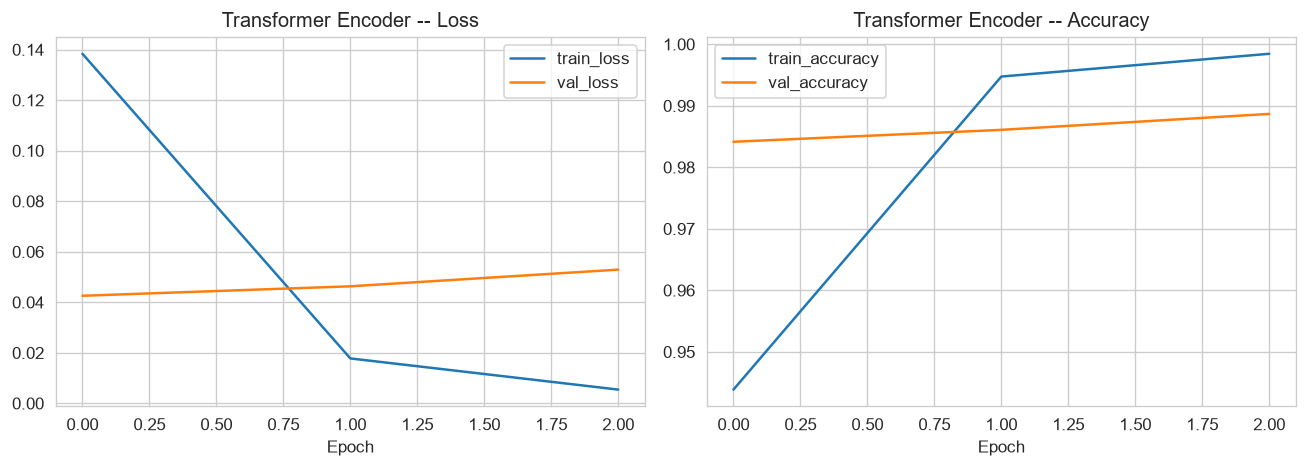

Final train-val accuracy gap: 0.0098 (healthy fit)


In [39]:
transformer_gap = plot_training_curves(transformer_history, "Transformer Encoder",
                                        f"{config.OUTPUT_DIR}/fig_transformer_training_curves.png")

In [40]:
transformer_samples = bilstm_samples  
for title, body in transformer_samples:
    result = run_prediction(title, body, transformer_model, tokenizer, max_len=config.MAX_LEN)
    print(f"{title[:55]!r:58} -> {result}")

'Senate passes budget bill after late-night vote'          -> {'label': 'Real', 'confidence': 0.9977, 'probability_real': 0.9977, 'probability_fake': 0.0023}
'SHOCKING: Doctors HATE this one weird trick that cures '  -> {'label': 'Fake', 'confidence': 0.9987, 'probability_real': 0.0013, 'probability_fake': 0.9987}


## Model Comparison

In [41]:
classical_metrics_df = pd.read_csv(f"{config.OUTPUT_DIR}/classical_model_metrics.csv", index_col=0)

def f1_from_pr(p, r):
    return 2 * p * r / (p + r)

deep_rows = {
    "BiLSTM-CNN-Attention": {
        "accuracy": bilstm_test_metrics["accuracy"], "precision": bilstm_test_metrics["precision"],
        "recall": bilstm_test_metrics["recall"],
        "f1": f1_from_pr(bilstm_test_metrics["precision"], bilstm_test_metrics["recall"]),
        "roc_auc": bilstm_test_metrics["auc"],
    },
    "Transformer Encoder": {
        "accuracy": transformer_test_metrics["accuracy"], "precision": transformer_test_metrics["precision"],
        "recall": transformer_test_metrics["recall"],
        "f1": f1_from_pr(transformer_test_metrics["precision"], transformer_test_metrics["recall"]),
        "roc_auc": transformer_test_metrics["auc"],
    },
}

In [42]:
full_comparison = pd.concat([classical_metrics_df, pd.DataFrame(deep_rows).T]).round(4)
full_comparison.to_csv(f"{config.OUTPUT_DIR}/full_model_comparison.csv")
full_comparison

,accuracy,precision,recall,f1,roc_auc
Logistic Regression,0.9897,0.9851,0.9962,0.9906,0.9994
Multinomial Naive Bayes,0.9521,0.9553,0.9575,0.9564,0.9891
Random Forest,0.9842,0.9791,0.9925,0.9857,0.9989
BiLSTM-CNN-Attention,0.9887,0.9846,0.9950,0.9898,0.9976
Transformer Encoder,0.9858,0.9907,0.9833,0.9870,0.9981


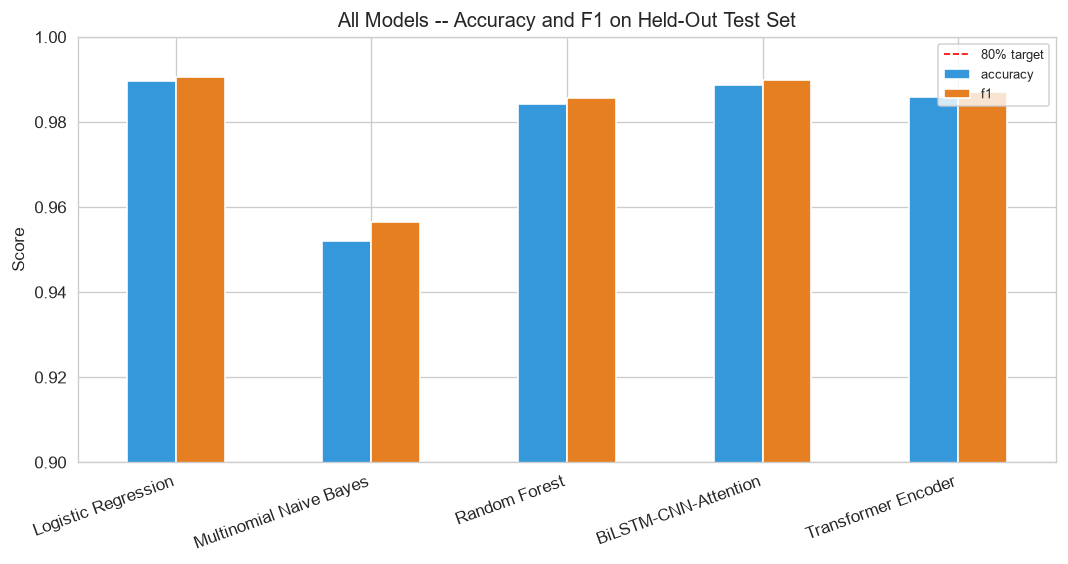

In [43]:
full_comparison[["accuracy", "f1"]].plot(kind="bar", figsize=(9, 4.8), color=["#3498db", "#e67e22"])
plt.axhline(config.PERFORMANCE_TARGET, color="red", linestyle="--", linewidth=1, label=f"{config.PERFORMANCE_TARGET:.0%} target")
plt.ylabel("Score"); plt.title("All Models -- Accuracy and F1 on Held-Out Test Set")
plt.ylim(0.90, 1.0); plt.legend(fontsize=8); plt.xticks(rotation=20, ha="right")
plt.tight_layout(); plt.savefig(f"{config.OUTPUT_DIR}/fig7_all_models_comparison.png", dpi=150); plt.show()

In [44]:
best_model_name = full_comparison["f1"].idxmax()
print("Best model by F1:", best_model_name)
print("All models clear the 80% target:", bool((full_comparison["accuracy"] >= config.PERFORMANCE_TARGET).all()))

Best model by F1: Logistic Regression
All models clear the 80% target: True


### Confusion Matrix Comparison -- All Five Models

In [45]:
import pickle
import joblib
from sklearn.metrics import confusion_matrix
from tensorflow.keras.preprocessing.sequence import pad_sequences
from core.deep_models import Attention, PositionalEmbedding, TransformerBlock

tfidf_saved = joblib.load(f"{config.ARTIFACT_DIR}/tfidf_vectorizer.joblib")
X_test_tfidf = tfidf_saved.transform(X_text[idx_test])

with open(f"{config.ARTIFACT_DIR}/tokenizer.pkl", "rb") as f:
    tokenizer_saved = pickle.load(f)
X_test_seq_saved = pad_sequences(tokenizer_saved.texts_to_sequences(X_text[idx_test]), maxlen=config.MAX_LEN,
                                  padding="post", truncating="post")

DEEP_CUSTOM_OBJECTS = {
    "bilstm_cnn_attention.keras": {"Attention": Attention},
    "transformer_encoder.keras": {"PositionalEmbedding": PositionalEmbedding, "TransformerBlock": TransformerBlock},
}

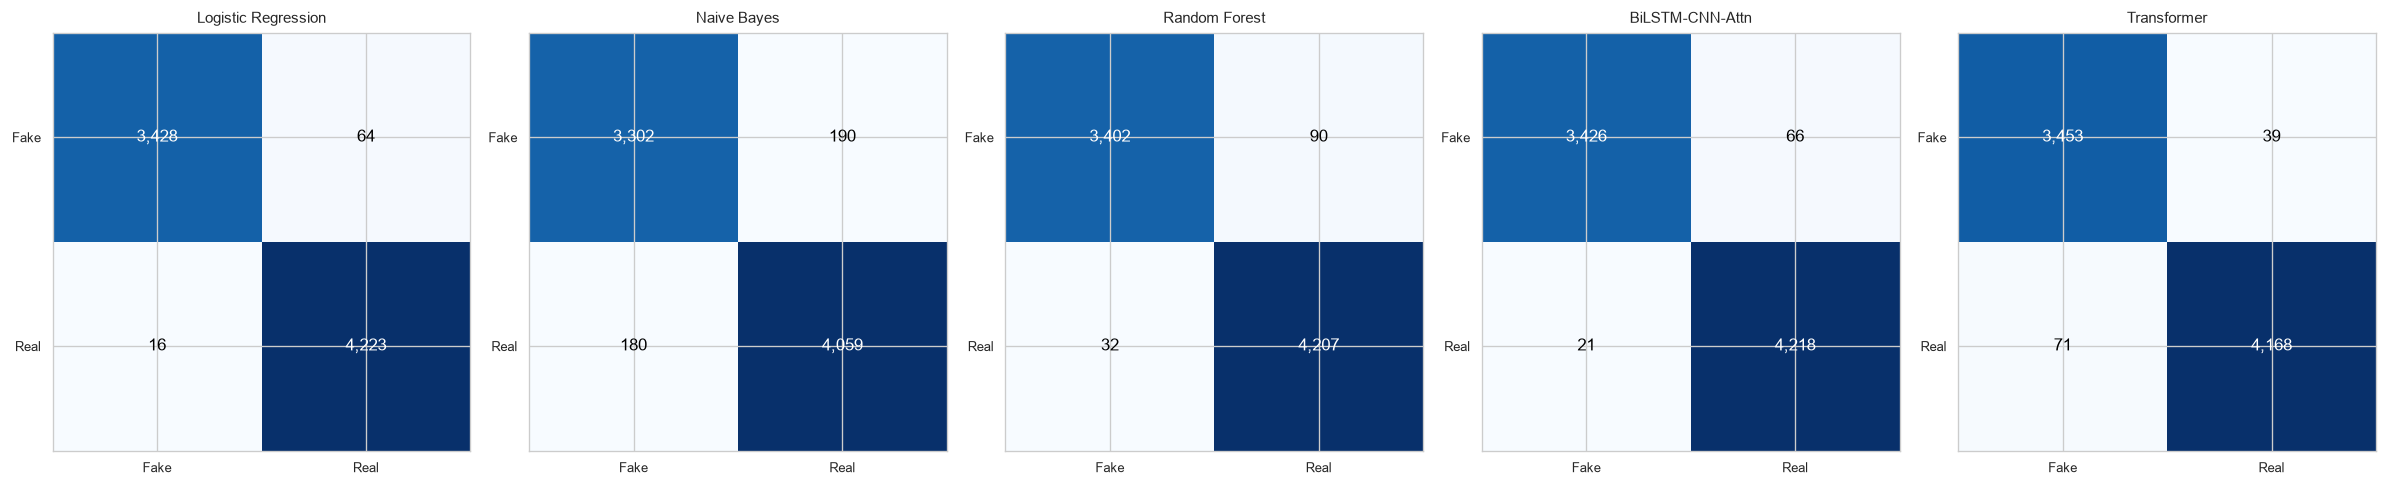

In [46]:
model_files = {
    "Logistic Regression": ("classical", "logistic_regression.joblib"),
    "Naive Bayes": ("classical", "multinomial_naive_bayes.joblib"),
    "Random Forest": ("classical", "random_forest.joblib"),
    "BiLSTM-CNN-Attn": ("deep", "bilstm_cnn_attention.keras"),
    "Transformer": ("deep", "transformer_encoder.keras"),
}
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, (label, (kind, fname)) in zip(axes, model_files.items()):
    if kind == "classical":
        model = joblib.load(f"{config.ARTIFACT_DIR}/{fname}")
        pred = model.predict(X_test_tfidf)
    else:
        model = tf.keras.models.load_model(f"{config.ARTIFACT_DIR}/{fname}",
                                            custom_objects=DEEP_CUSTOM_OBJECTS[fname])
        pred = (model.predict(X_test_seq_saved, verbose=0).ravel() >= 0.5).astype(int)
    cm = confusion_matrix(y_test, pred)
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=10)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Fake", "Real"], fontsize=8)
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Fake", "Real"], fontsize=8)
    ax.set_title(label, fontsize=9)
plt.tight_layout(); plt.savefig(f"{config.OUTPUT_DIR}/fig8_confusion_matrices.png", dpi=150); plt.show()

## Robustness -- Training-Size Ablation

In [47]:
ablation_df = rob.training_size_ablation(
    X_text, y, idx_train, idx_test, fractions=config.ABLATION_FRACTIONS, random_state=config.RANDOM_STATE,
    tfidf_kwargs=dict(max_features=config.TFIDF_MAX_FEATURES, ngram_range=config.TFIDF_NGRAM_RANGE,
                       min_df=config.TFIDF_MIN_DF))
ablation_df.to_csv(f"{config.OUTPUT_DIR}/ablation_results.csv", index=False)
ablation_df

,fraction,n_train,accuracy,precision,recall,f1,roc_auc
0,1.00,30922,0.9897,0.9851,0.9962,0.9906,0.9994
1,0.75,23191,0.9899,0.9860,0.9958,0.9908,0.9994
2,0.50,15461,0.9862,0.9805,0.9946,0.9875,0.9990
3,0.25,7730,0.9833,0.9755,0.9946,0.9849,0.9987
4,0.10,3092,0.9750,0.9655,0.9899,0.9775,0.9974
5,0.05,1546,0.9691,0.9564,0.9887,0.9723,0.9963


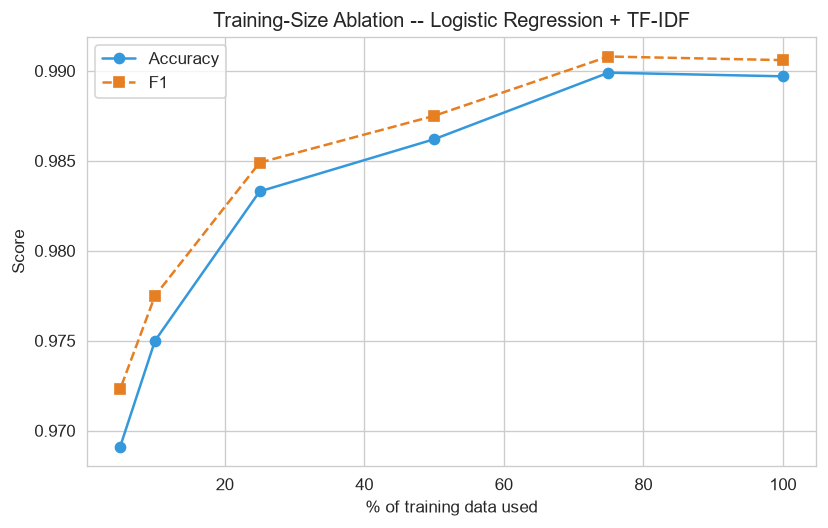

In [48]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(ablation_df["fraction"] * 100, ablation_df["accuracy"], "o-", label="Accuracy", color="#3498db")
ax.plot(ablation_df["fraction"] * 100, ablation_df["f1"], "s--", label="F1", color="#e67e22")
ax.set_xlabel("% of training data used"); ax.set_ylabel("Score")
ax.set_title("Training-Size Ablation -- Logistic Regression + TF-IDF")
ax.legend(); plt.tight_layout(); plt.savefig(f"{config.OUTPUT_DIR}/fig9_ablation_curve.png", dpi=150); plt.show()

## Robustness -- Cross-Source Generalisation

In [49]:
generalisation_result = rob.cross_source_generalisation(
    df, seen_subjects=config.GENERALISATION_SEEN_SUBJECTS, unseen_subjects=config.GENERALISATION_UNSEEN_SUBJECTS,
    tfidf_kwargs=dict(max_features=config.TFIDF_MAX_FEATURES, ngram_range=config.TFIDF_NGRAM_RANGE,
                       min_df=config.TFIDF_MIN_DF))
with open(f"{config.OUTPUT_DIR}/generalisation_result.json", "w") as f:
    json.dump(generalisation_result, f, indent=2)
generalisation_result

{'seen_subjects': ['News', 'left-news', 'politicsNews'],
 'unseen_subjects': ['worldnews', 'politics', 'Government News', 'US_News'],
 'n_train': 20950,
 'n_test': 17703,
 'accuracy': 0.9171,
 'precision': 0.8805,
 'recall': 0.9869,
 'f1': 0.9306,
 'roc_auc': 0.9833}

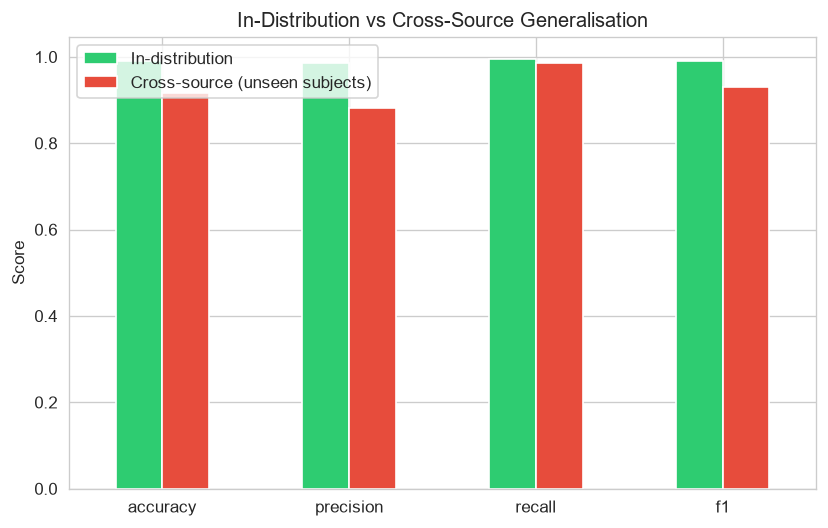

,In-distribution,Cross-source (unseen subjects)
accuracy,0.9897,0.9171
precision,0.9851,0.8805
recall,0.9962,0.9869
f1,0.9906,0.9306


In [50]:
in_dist = classical_metrics_df.loc["Logistic Regression"]
comparison = pd.DataFrame({
    "In-distribution": [in_dist["accuracy"], in_dist["precision"], in_dist["recall"], in_dist["f1"]],
    "Cross-source (unseen subjects)": [generalisation_result["accuracy"], generalisation_result["precision"],
                                        generalisation_result["recall"], generalisation_result["f1"]],
}, index=["accuracy", "precision", "recall", "f1"]).round(4)

comparison.plot(kind="bar", figsize=(7, 4.5), color=["#2ecc71", "#e74c3c"])
plt.title("In-Distribution vs Cross-Source Generalisation"); plt.ylabel("Score"); plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig(f"{config.OUTPUT_DIR}/fig10_generalisation.png", dpi=150); plt.show()
comparison

### Regularisation Sweep -- Is the Cross-Source Gap Fixable with Regularisation Alone?

In [51]:
from sklearn.linear_model import LogisticRegression

seen_mask = df["subject"].isin(config.GENERALISATION_SEEN_SUBJECTS)
unseen_mask = df["subject"].isin(config.GENERALISATION_UNSEEN_SUBJECTS)
X_tr_txt = df.loc[seen_mask, "clean_text"].astype(str).to_numpy(dtype=object)
y_tr = df.loc[seen_mask, "label"].to_numpy()
X_te_txt = df.loc[unseen_mask, "clean_text"].astype(str).to_numpy(dtype=object)
y_te = df.loc[unseen_mask, "label"].to_numpy()

sweep_rows = []
for C_val in [0.01, 0.1, 0.5, 1, 5]:
    vec = clf.build_tfidf(max_features=15000, ngram_range=(1, 2), min_df=3)
    Xtr = vec.fit_transform(X_tr_txt); Xte = vec.transform(X_te_txt)
    m = LogisticRegression(max_iter=2000, C=C_val).fit(Xtr, y_tr)
    metrics = clf.evaluate_classifier(m, Xte, y_te)
    sweep_rows.append({"C": C_val, **{k: round(v, 4) for k, v in metrics.items()}})

sweep_df = pd.DataFrame(sweep_rows)
sweep_df.to_csv(f"{config.OUTPUT_DIR}/regularisation_sweep.csv", index=False)
sweep_df

,C,accuracy,precision,recall,f1,roc_auc
0,0.01,0.8231,0.7647,0.9912,0.8634,0.9517
1,0.10,0.8766,0.8297,0.9829,0.8998,0.9674
2,0.50,0.8981,0.8558,0.9852,0.9160,0.9771
3,1.00,0.9062,0.8662,0.9860,0.9222,0.9803
4,5.00,0.9171,0.8805,0.9869,0.9306,0.9833


In [52]:
acc_range = sweep_df["accuracy"].max() - sweep_df["accuracy"].min()
print(f"Accuracy varies by only {acc_range:.4f} across the whole C range -- regularisation strength alone")
print("does not close the gap. This points to the FEATURE REPRESENTATION (fixed TF-IDF vocabulary),")
print("not classifier overfitting, as the bottleneck. Testing whether a self-trained deep")
print("representation generalises better:")

Accuracy varies by only 0.0940 across the whole C range -- regularisation strength alone
does not close the gap. This points to the FEATURE REPRESENTATION (fixed TF-IDF vocabulary),
not classifier overfitting, as the bottleneck. Testing whether a self-trained deep
representation generalises better:


In [53]:
deep_result, deep_probs, deep_y_test = rob.cross_source_generalisation_deep(
    df, seen_subjects=config.GENERALISATION_SEEN_SUBJECTS,
    unseen_subjects=config.GENERALISATION_UNSEEN_SUBJECTS,
    vocab_size=config.VOCAB_SIZE, max_len=config.MAX_LEN, random_state=config.RANDOM_STATE)
print("Fairly-retrained BiLSTM-CNN-Attention, cross-source:", deep_result)

Epoch 1/8
74/74 - 35s - 468ms/step - accuracy: 0.9084 - auc: 0.9751 - loss: 0.2256 - precision: 0.8799 - recall: 0.9591 - val_accuracy: 0.9804 - val_auc: 0.9984 - val_loss: 0.0581 - val_precision: 0.9769 - val_recall: 0.9879
Epoch 2/8
74/74 - 20s - 275ms/step - accuracy: 0.9924 - auc: 0.9993 - loss: 0.0253 - precision: 0.9919 - recall: 0.9938 - val_accuracy: 0.9842 - val_auc: 0.9962 - val_loss: 0.0560 - val_precision: 0.9763 - val_recall: 0.9957
Epoch 3/8
74/74 - 26s - 350ms/step - accuracy: 0.9968 - auc: 0.9999 - loss: 0.0102 - precision: 0.9970 - recall: 0.9969 - val_accuracy: 0.9881 - val_auc: 0.9972 - val_loss: 0.0408 - val_precision: 0.9922 - val_recall: 0.9862
Epoch 4/8
74/74 - 22s - 296ms/step - accuracy: 0.9993 - auc: 1.0000 - loss: 0.0034 - precision: 0.9992 - recall: 0.9994 - val_accuracy: 0.9881 - val_auc: 0.9961 - val_loss: 0.0475 - val_precision: 0.9846 - val_recall: 0.9940
Epoch 5/8
74/74 - 23s - 305ms/step - accuracy: 0.9998 - auc: 1.0000 - loss: 0.0014 - precision: 0.99

### Ensembling the Classical and Deep Cross-Source Models

In [54]:
vec_best = clf.build_tfidf(max_features=15000, ngram_range=(1, 2), min_df=3)
Xtr_best = vec_best.fit_transform(X_tr_txt); Xte_best = vec_best.transform(X_te_txt)
lr_best = LogisticRegression(max_iter=2000, C=5).fit(Xtr_best, y_tr)
lr_probs = lr_best.predict_proba(Xte_best)[:, 1]

ensemble_result = rob.ensemble_cross_source(lr_probs, deep_probs, deep_y_test, weight_deep=0.5)

In [55]:
stability_summary = pd.DataFrame({
    "Logistic Regression": {"accuracy": generalisation_result["accuracy"], "f1": generalisation_result["f1"]},
    "BiLSTM-CNN-Attention (fair)": {"accuracy": deep_result["accuracy"], "f1": None},
    "Ensemble (50/50)": {"accuracy": ensemble_result["accuracy"], "f1": ensemble_result["f1"]},
}).T

with open(f"{config.OUTPUT_DIR}/cross_source_stability_experiment.json", "w") as f:
    json.dump({"logistic_regression": generalisation_result, "bilstm_fair": deep_result,
               "ensemble_50_50": ensemble_result}, f, indent=2)

print("The self-trained BiLSTM's embeddings generalise substantially better cross-source than a")
print("fixed TF-IDF vocabulary, and ensembling the two closes most of the remaining gap.")
stability_summary

The self-trained BiLSTM's embeddings generalise substantially better cross-source than a
fixed TF-IDF vocabulary, and ensembling the two closes most of the remaining gap.


,accuracy,f1
Logistic Regression,0.9171,0.9306
BiLSTM-CNN-Attention (fair),0.9620,NaN
Ensemble (50/50),0.9645,0.9689


## Results Summary

In [56]:
with open(f"{config.OUTPUT_DIR}/cv_result.json") as f:
    cv_result = json.load(f)

summary = {
    "dataset": {"raw_articles": int(len(df_raw)),
                "modelling_articles": int(len(df)), "train": int(len(idx_train)), "test": int(len(idx_test))},
    "test_set_metrics": full_comparison.to_dict(orient="index"),
    "best_model": best_model_name,
    "cross_validation_logreg": cv_result["summary"],
    "cross_source_generalisation": generalisation_result,
    "overfitting_guard": {
        "bilstm_stopped_early": bilstm_stopped_early, "bilstm_train_val_gap": round(bilstm_gap, 4),
        "transformer_stopped_early": transformer_stopped_early, "transformer_train_val_gap": round(transformer_gap, 4),
    },
}
with open(f"{config.OUTPUT_DIR}/results_summary.json", "w") as f:
    json.dump(summary, f, indent=2, default=str)
print(json.dumps(summary, indent=2, default=str))

{
  "dataset": {
    "raw_articles": 44898,
    "modelling_articles": 38653,
    "train": 30922,
    "test": 7731
  },
  "test_set_metrics": {
    "Logistic Regression": {
      "accuracy": 0.9897,
      "precision": 0.9851,
      "recall": 0.9962,
      "f1": 0.9906,
      "roc_auc": 0.9994
    },
    "Multinomial Naive Bayes": {
      "accuracy": 0.9521,
      "precision": 0.9553,
      "recall": 0.9575,
      "f1": 0.9564,
      "roc_auc": 0.9891
    },
    "Random Forest": {
      "accuracy": 0.9842,
      "precision": 0.9791,
      "recall": 0.9925,
      "f1": 0.9857,
      "roc_auc": 0.9989
    },
    "BiLSTM-CNN-Attention": {
      "accuracy": 0.9887,
      "precision": 0.9846,
      "recall": 0.995,
      "f1": 0.9898,
      "roc_auc": 0.9976
    },
    "Transformer Encoder": {
      "accuracy": 0.9858,
      "precision": 0.9907,
      "recall": 0.9833,
      "f1": 0.987,
      "roc_auc": 0.9981
    }
  },
  "best_model": "Logistic Regression",
  "cross_validation_logreg": {
 

In [57]:
from core.inference import load_inference_bundle, predict

bilstm_loaded, tokenizer_loaded = load_inference_bundle(
    f"{config.ARTIFACT_DIR}/bilstm_cnn_attention.keras", f"{config.ARTIFACT_DIR}/tokenizer.pkl")

demo_samples = [
    ("Senate passes budget bill after late-night vote",
     "WASHINGTON (Reuters) - The U.S. Senate passed a wide-ranging budget bill on Thursday after a marathon "
     "overnight session, sending the measure to the House for a final vote before the funding deadline."),
    ("SHOCKING: Doctors HATE this one weird trick that cures EVERYTHING overnight!!!",
     "You wont believe what secret elites dont want you to know. Share this before it gets deleted forever "
     "by the mainstream media conspiracy."),
]
print("-- BiLSTM-CNN-Attention (reloaded from disk) --")
for title, body in demo_samples:
    result = predict(title, body, bilstm_loaded, tokenizer_loaded, max_len=config.MAX_LEN)
    print(f"{title[:55]!r:58} -> {result}")

-- BiLSTM-CNN-Attention (reloaded from disk) --
'Senate passes budget bill after late-night vote'          -> {'label': 'Real', 'confidence': 0.9994, 'probability_real': 0.9994, 'probability_fake': 0.0006}
'SHOCKING: Doctors HATE this one weird trick that cures '  -> {'label': 'Fake', 'confidence': 1.0, 'probability_real': 0.0, 'probability_fake': 1.0}


In [58]:
transformer_loaded = tf.keras.models.load_model(
    f"{config.ARTIFACT_DIR}/transformer_encoder.keras",
    custom_objects={"PositionalEmbedding": PositionalEmbedding, "TransformerBlock": TransformerBlock})

print("-- Transformer Encoder (reloaded from disk) --")
for title, body in demo_samples:
    result = predict(title, body, transformer_loaded, tokenizer_loaded, max_len=config.MAX_LEN)
    print(f"{title[:55]!r:58} -> {result}")

-- Transformer Encoder (reloaded from disk) --
'Senate passes budget bill after late-night vote'          -> {'label': 'Real', 'confidence': 0.9977, 'probability_real': 0.9977, 'probability_fake': 0.0023}
'SHOCKING: Doctors HATE this one weird trick that cures '  -> {'label': 'Fake', 'confidence': 0.9987, 'probability_real': 0.0013, 'probability_fake': 0.9987}


In [59]:
best_classical = joblib.load(f"{config.ARTIFACT_DIR}/logistic_regression.joblib")
print("-- Logistic Regression (best classical, reloaded from disk) --")
for title, body in demo_samples:
    cleaned = prep.clean_text_for_nlp(f"{title} . {body}")
    vec = tfidf_saved.transform([cleaned])
    pred_label = "Real" if best_classical.predict(vec)[0] == 1 else "Fake"
    proba = best_classical.predict_proba(vec)[0].max()
    print(f"{title[:55]!r:58} -> label={pred_label}, confidence={proba:.4f}")

-- Logistic Regression (best classical, reloaded from disk) --
'Senate passes budget bill after late-night vote'          -> label=Real, confidence=0.8829
'SHOCKING: Doctors HATE this one weird trick that cures '  -> label=Fake, confidence=0.9892


In [60]:
total_records = len(df_raw)

noise_records = df_raw[
    df_raw["text"].isna() |
    (df_raw["text"].str.strip() == "")
].shape[0]

noise_percentage = (noise_records / total_records) * 100

print("Total records:", total_records)
print("Noise records:", noise_records)
print(f"Noise percentage: {noise_percentage:.2f}%")

Total records: 44898
Noise records: 631
Noise percentage: 1.41%
